In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Heart Disease 2026: Complete EDA & Baseline

> **Dataset:** Heart Disease Prediction Dataset 2026 · 100,000 rows · 25 features  
> **Target:** `heart_disease` (binary: 0 = No, 1 = Yes)  
> **Goal of this notebook:** Understand the data deeply, visualize every feature group, identify the strongest predictors, and build a baseline ML model - all from scratch.

---

## Table of Contents
1. [Setup & Data Load](#1-setup)
2. [Dataset Overview](#2-overview)
3. [Target Variable Analysis](#3-target)
4. [Demographics](#4-demographics)
5. [Clinical Markers](#5-clinical)
6. [Lifestyle Features](#6-lifestyle)
7. [Medical History](#7-medical-history)
8. [Wearable Signals](#8-wearables)
9. [Correlation Analysis](#9-correlation)
10. [Feature Importance (Baseline)](#10-feature-importance)
11. [Baseline Model](#11-baseline-model)
12. [Key Takeaways](#12-takeaways)


## 1. Setup & Data Load

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

# Style
plt.rcParams.update({
    'figure.facecolor': '#ffffff',
    'axes.facecolor':   '#f8f8f8',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.grid':        True,
    'grid.color':       '#e0e0e0',
    'grid.linewidth':   0.6,
    'font.family':      'DejaVu Sans',
    'font.size':        11,
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
POS_COLOR = '#e34948'
NEG_COLOR = '#2a78d6'

df = pd.read_csv('./data/heart_disease_prediction_2026.csv')
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")
df.head()

Shape: (100000, 26)
Missing values: 0
Duplicates: 0


,age,sex,bmi,region,income_level,smoking_status,alcohol_intake,physical_activity,diet_quality,sleep_hours,...,cholesterol,fasting_blood_sugar,max_heart_rate,resting_ecg,exercise_angina,st_depression,st_slope,avg_resting_hr,hrv_score,heart_disease
0,57,Male,27.1,Northeast,Middle,Never,Moderate,Light,7,5.7,...,204,0,195,Normal,0,0.9,Downsloping,61.8,19.9,0
1,40,Female,29.0,Northeast,Low,Never,Non-drinker,Sedentary,1,8.0,...,173,0,165,ST-T Abnormality,0,0.5,Downsloping,53.2,48.3,0
2,63,Female,40.1,Southeast,High,Never,Moderate,Sedentary,6,5.5,...,209,0,173,Normal,0,2.3,Downsloping,82.3,5.0,1
3,66,Female,35.5,West,Middle,Never,Heavy,Sedentary,10,7.4,...,187,0,144,Normal,0,1.3,Downsloping,71.1,38.3,1
4,29,Female,19.8,Northeast,High,Current,Non-drinker,Sedentary,8,8.3,...,247,0,170,ST-T Abnormality,0,0.4,Downsloping,74.1,49.4,0


## 2. Dataset Overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   age                   100000 non-null  int64  
 1   sex                   100000 non-null  str    
 2   bmi                   100000 non-null  float64
 3   region                100000 non-null  str    
 4   income_level          100000 non-null  str    
 5   smoking_status        100000 non-null  str    
 6   alcohol_intake        100000 non-null  str    
 7   physical_activity     100000 non-null  str    
 8   diet_quality          100000 non-null  int64  
 9   sleep_hours           100000 non-null  float64
 10  stress_level          100000 non-null  int64  
 11  diabetes              100000 non-null  int64  
 12  hypertension          100000 non-null  int64  
 13  family_history        100000 non-null  int64  
 14  previous_heart_event  100000 non-null  int64  
 15  resting_bp  

In [5]:
df.describe().round(2)

,age,bmi,diet_quality,sleep_hours,stress_level,diabetes,hypertension,family_history,previous_heart_event,resting_bp,cholesterol,fasting_blood_sugar,max_heart_rate,exercise_angina,st_depression,avg_resting_hr,hrv_score,heart_disease
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,53.50,28.06,5.82,6.91,5.73,0.11,0.47,0.30,0.03,142.06,217.67,0.14,174.25,0.26,1.39,70.03,52.79,0.46
std,12.45,5.46,2.01,1.09,2.19,0.31,0.50,0.46,0.17,25.08,48.20,0.35,14.79,0.44,1.05,12.51,19.38,0.50
min,29.00,15.00,1.00,4.00,1.00,0.00,0.00,0.00,0.00,80.00,100.00,0.00,107.00,0.00,0.00,40.00,5.00,0.00
25%,45.00,24.30,4.00,6.20,4.00,0.00,0.00,0.00,0.00,124.00,185.00,0.00,164.00,0.00,0.60,61.50,39.50,0.00
50%,53.00,28.00,6.00,6.90,6.00,0.00,0.00,0.00,0.00,141.00,218.00,0.00,174.00,0.00,1.10,70.00,52.90,0.00
75%,62.00,31.70,7.00,7.60,7.00,0.00,1.00,1.00,0.00,160.00,251.00,0.00,185.00,1.00,2.00,78.50,66.00,1.00
max,80.00,54.60,10.00,10.00,10.00,1.00,1.00,1.00,1.00,200.00,400.00,1.00,202.00,1.00,6.20,110.00,100.00,1.00


In [6]:
# Categorical columns — value counts
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


sex:
sex
Male      55176
Female    44824
Name: count, dtype: int64

region:
region
Southeast    25087
Midwest      21956
Northeast    18103
West         17885
Southwest    16969
Name: count, dtype: int64

income_level:
income_level
Middle    45006
Low       30147
High      24847
Name: count, dtype: int64

smoking_status:
smoking_status
Never      61887
Former     24182
Current    13931
Name: count, dtype: int64

alcohol_intake:
alcohol_intake
Moderate       48038
Non-drinker    37898
Heavy          14064
Name: count, dtype: int64

physical_activity:
physical_activity
Sedentary      29715
Light          28303
Active         24392
Very Active    17590
Name: count, dtype: int64

resting_ecg:
resting_ecg
Normal                          45940
ST-T Abnormality                35486
Left Ventricular Hypertrophy    18574
Name: count, dtype: int64

st_slope:
st_slope
Upsloping      42769
Flat           38594
Downsloping    18637
Name: count, dtype: int64


## 3. Target Variable Analysis

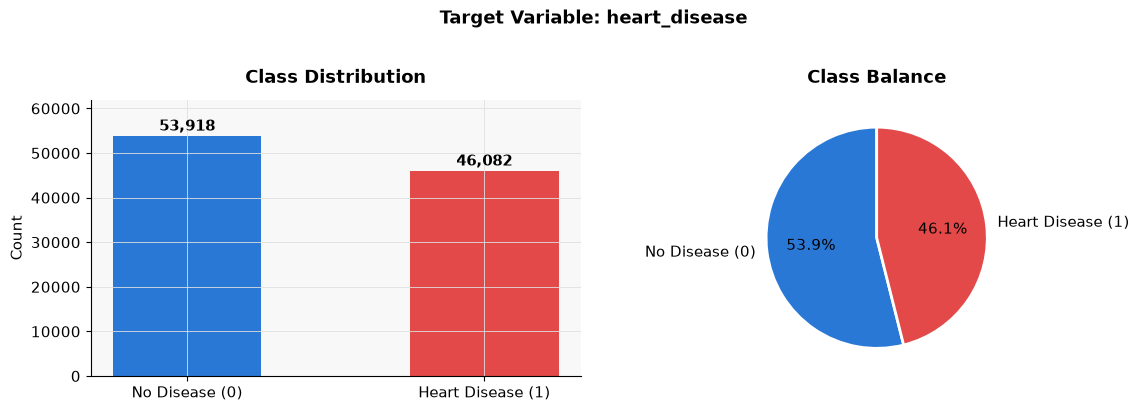

Positive rate: 0.461 (46,082 / 100,000)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
counts = df['heart_disease'].value_counts()
labels = ['No Disease (0)', 'Heart Disease (1)']
bars = axes[0].bar(labels, counts.values, color=[NEG_COLOR, POS_COLOR],
                   width=0.5, edgecolor='none')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Class Distribution', fontweight='bold', pad=12)
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, counts.max() * 1.15)

# Pie chart
axes[1].pie(counts.values, labels=labels, colors=[NEG_COLOR, POS_COLOR],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Balance', fontweight='bold', pad=12)

plt.suptitle('Target Variable: heart_disease', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Positive rate: {df.heart_disease.mean():.3f} ({df.heart_disease.sum():,} / {len(df):,})")

## 4. Demographics

Age, sex, BMI, region, and income level form the foundation of cardiovascular risk stratification.

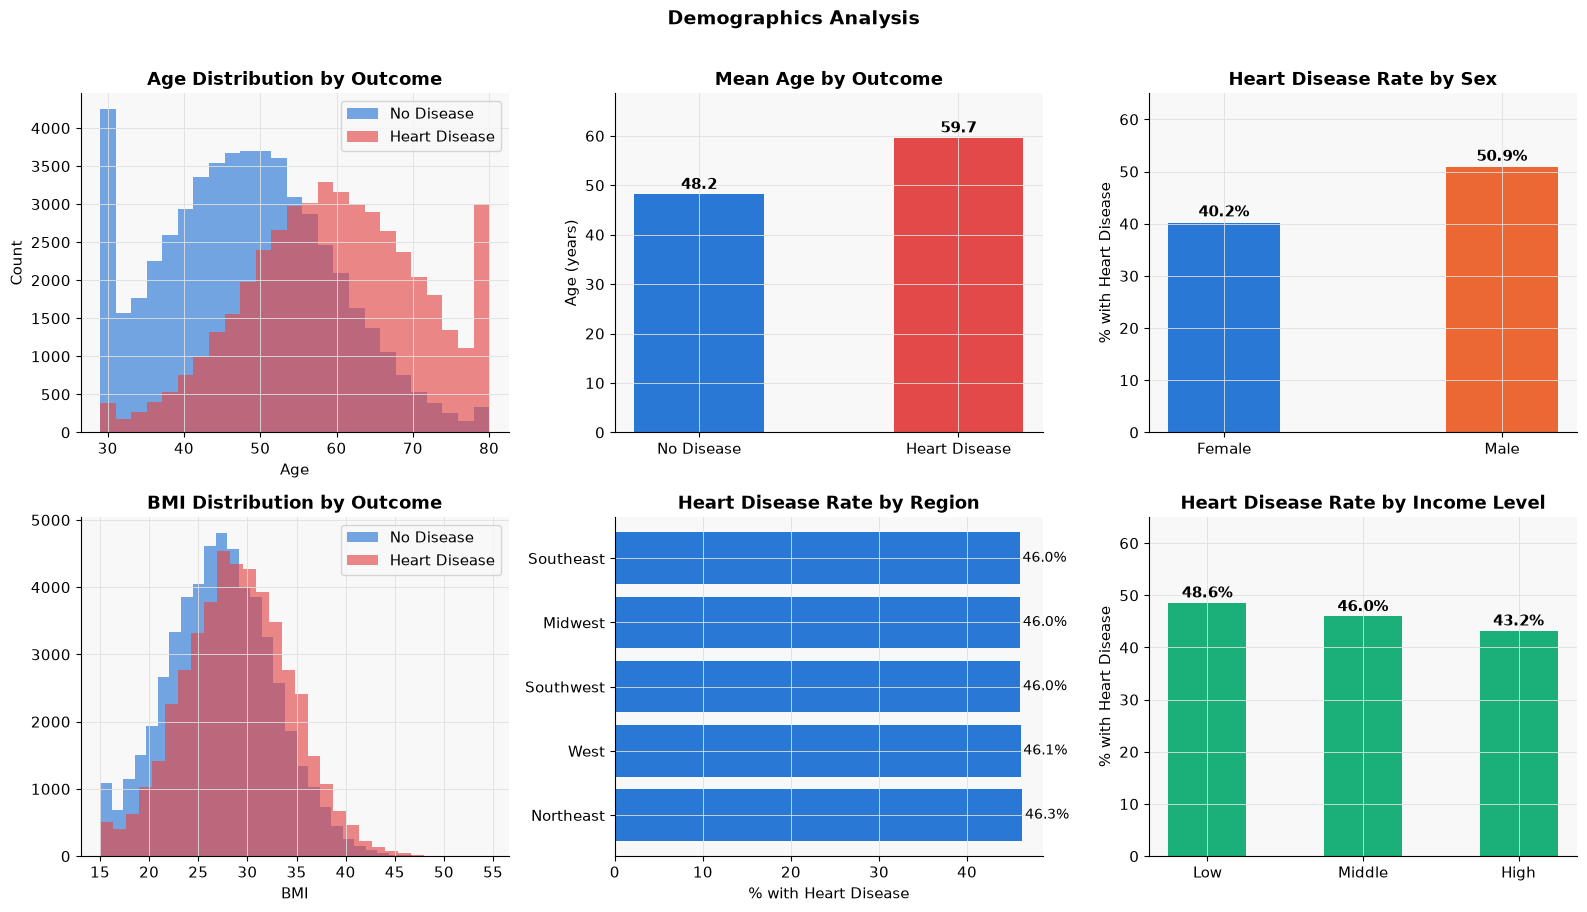

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Age distribution by disease status
for status, color, label in [(0, NEG_COLOR, 'No Disease'), (1, POS_COLOR, 'Heart Disease')]:
    axes[0,0].hist(df[df.heart_disease==status]['age'], bins=25, alpha=0.65,
                   color=color, label=label, edgecolor='none')
axes[0,0].set_title('Age Distribution by Outcome', fontweight='bold')
axes[0,0].set_xlabel('Age')
axes[0,0].set_ylabel('Count')
axes[0,0].legend()

# Mean age by disease
mean_age = df.groupby('heart_disease')['age'].mean()
bars = axes[0,1].bar(['No Disease', 'Heart Disease'], mean_age.values,
                     color=[NEG_COLOR, POS_COLOR], width=0.5, edgecolor='none')
for bar, val in zip(bars, mean_age.values):
    axes[0,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                   f'{val:.1f}', ha='center', va='bottom', fontweight='bold')
axes[0,1].set_title('Mean Age by Outcome', fontweight='bold')
axes[0,1].set_ylabel('Age (years)')
axes[0,1].set_ylim(0, mean_age.max()*1.15)

# Sex vs heart disease rate
sex_hd = df.groupby('sex')['heart_disease'].mean().reset_index()
bars = axes[0,2].bar(sex_hd['sex'], sex_hd['heart_disease']*100,
                     color=PALETTE[:2], width=0.4, edgecolor='none')
for bar, val in zip(bars, sex_hd['heart_disease']*100):
    axes[0,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                   f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[0,2].set_title('Heart Disease Rate by Sex', fontweight='bold')
axes[0,2].set_ylabel('% with Heart Disease')
axes[0,2].set_ylim(0, 65)

# BMI by disease
for status, color, label in [(0, NEG_COLOR, 'No Disease'), (1, POS_COLOR, 'Heart Disease')]:
    axes[1,0].hist(df[df.heart_disease==status]['bmi'], bins=30, alpha=0.65,
                   color=color, label=label, edgecolor='none')
axes[1,0].set_title('BMI Distribution by Outcome', fontweight='bold')
axes[1,0].set_xlabel('BMI')
axes[1,0].legend()

# Region HD rate
region_hd = df.groupby('region')['heart_disease'].mean().sort_values(ascending=False)
axes[1,1].barh(region_hd.index, region_hd.values*100,
               color=PALETTE[0], edgecolor='none')
axes[1,1].set_title('Heart Disease Rate by Region', fontweight='bold')
axes[1,1].set_xlabel('% with Heart Disease')
for i, val in enumerate(region_hd.values*100):
    axes[1,1].text(val+0.3, i, f'{val:.1f}%', va='center', fontsize=10)

# Income level HD rate
inc_hd = df.groupby('income_level')['heart_disease'].mean()
inc_order = ['Low', 'Middle', 'High']
inc_vals = [inc_hd[i]*100 for i in inc_order]
bars = axes[1,2].bar(inc_order, inc_vals, color=PALETTE[2], width=0.5, edgecolor='none')
for bar, val in zip(bars, inc_vals):
    axes[1,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                   f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[1,2].set_title('Heart Disease Rate by Income Level', fontweight='bold')
axes[1,2].set_ylabel('% with Heart Disease')
axes[1,2].set_ylim(0, 65)

plt.suptitle('Demographics Analysis', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 5. Clinical Markers

The 8 clinical markers are the core diagnostic features - they mirror what physicians measure during cardiovascular workups.

TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

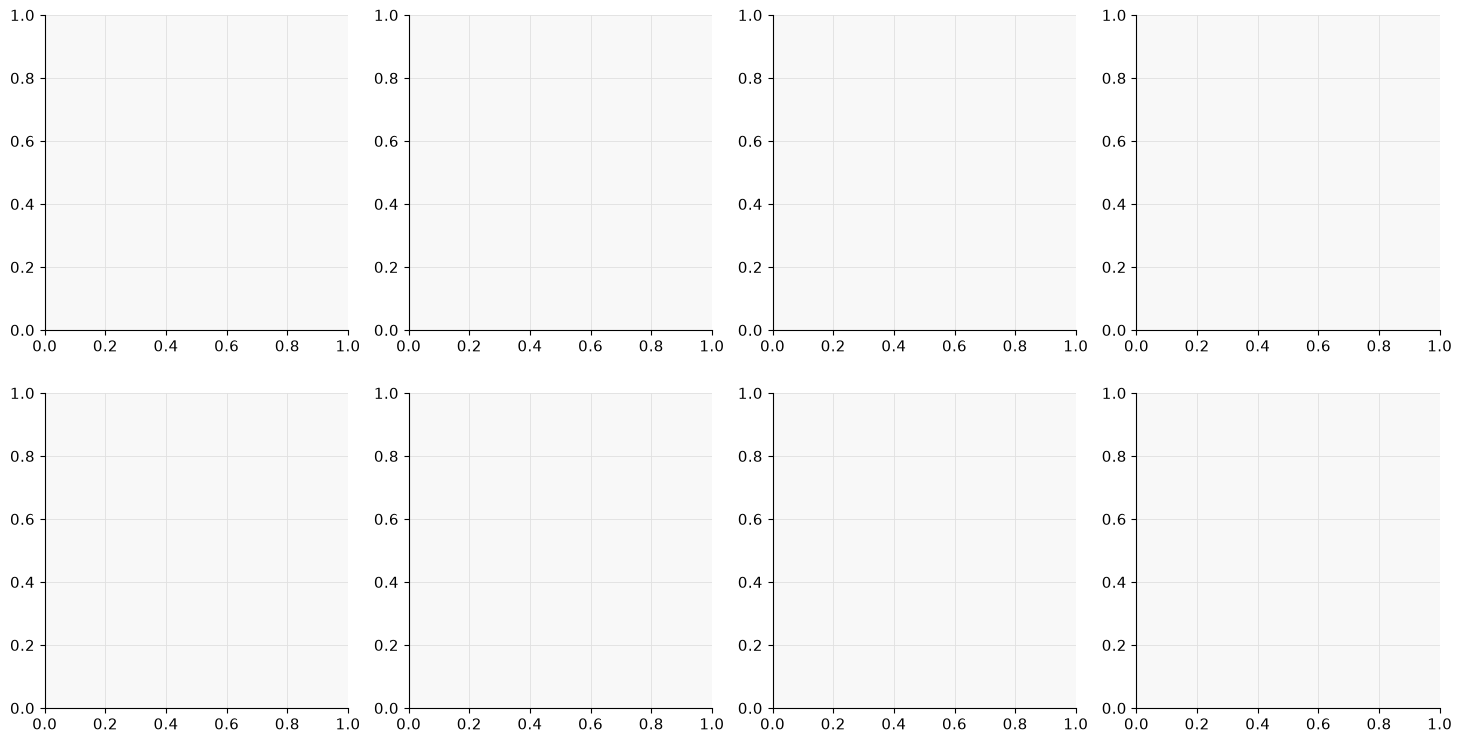

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

cont_clinical = ['resting_bp', 'cholesterol', 'max_heart_rate', 'st_depression']
cat_clinical  = ['resting_ecg', 'exercise_angina', 'fasting_blood_sugar', 'st_slope']

# Continuous — boxplots by outcome
for i, col in enumerate(cont_clinical):
    data_no  = df[df.heart_disease==0][col]
    data_yes = df[df.heart_disease==1][col]
    bp = axes[i].boxplot([data_no, data_yes],
                         patch_artist=True,
                         labels=['No Disease', 'Heart Disease'],
                         medianprops={'color':'white','linewidth':2})
    bp['boxes'][0].set_facecolor(NEG_COLOR)
    bp['boxes'][1].set_facecolor(POS_COLOR)
    for whisker in bp['whiskers']: whisker.set_color('#888')
    for cap in bp['caps']: cap.set_color('#888')
    axes[i].set_title(col.replace('_',' ').title(), fontweight='bold')
    axes[i].set_ylabel('Value')

# Categorical — HD rate bars
for i, col in enumerate(cat_clinical, start=4):
    cat_hd = df.groupby(col)['heart_disease'].mean().sort_values(ascending=False)
    colors = [POS_COLOR if v > 0.5 else PALETTE[0] for v in cat_hd.values]
    bars = axes[i].bar(range(len(cat_hd)), cat_hd.values*100,
                       color=colors, edgecolor='none')
    axes[i].set_xticks(range(len(cat_hd)))
    axes[i].set_xticklabels(cat_hd.index, rotation=20, ha='right', fontsize=9)
    axes[i].set_title(col.replace('_',' ').title(), fontweight='bold')
    axes[i].set_ylabel('% with Heart Disease')
    for bar, val in zip(bars, cat_hd.values*100):
        axes[i].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                     f'{val:.0f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Clinical Markers vs Heart Disease Outcome', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 6. Lifestyle Features

Lifestyle factors are increasingly recognized as modifiable risk factors with significant population-level impact.

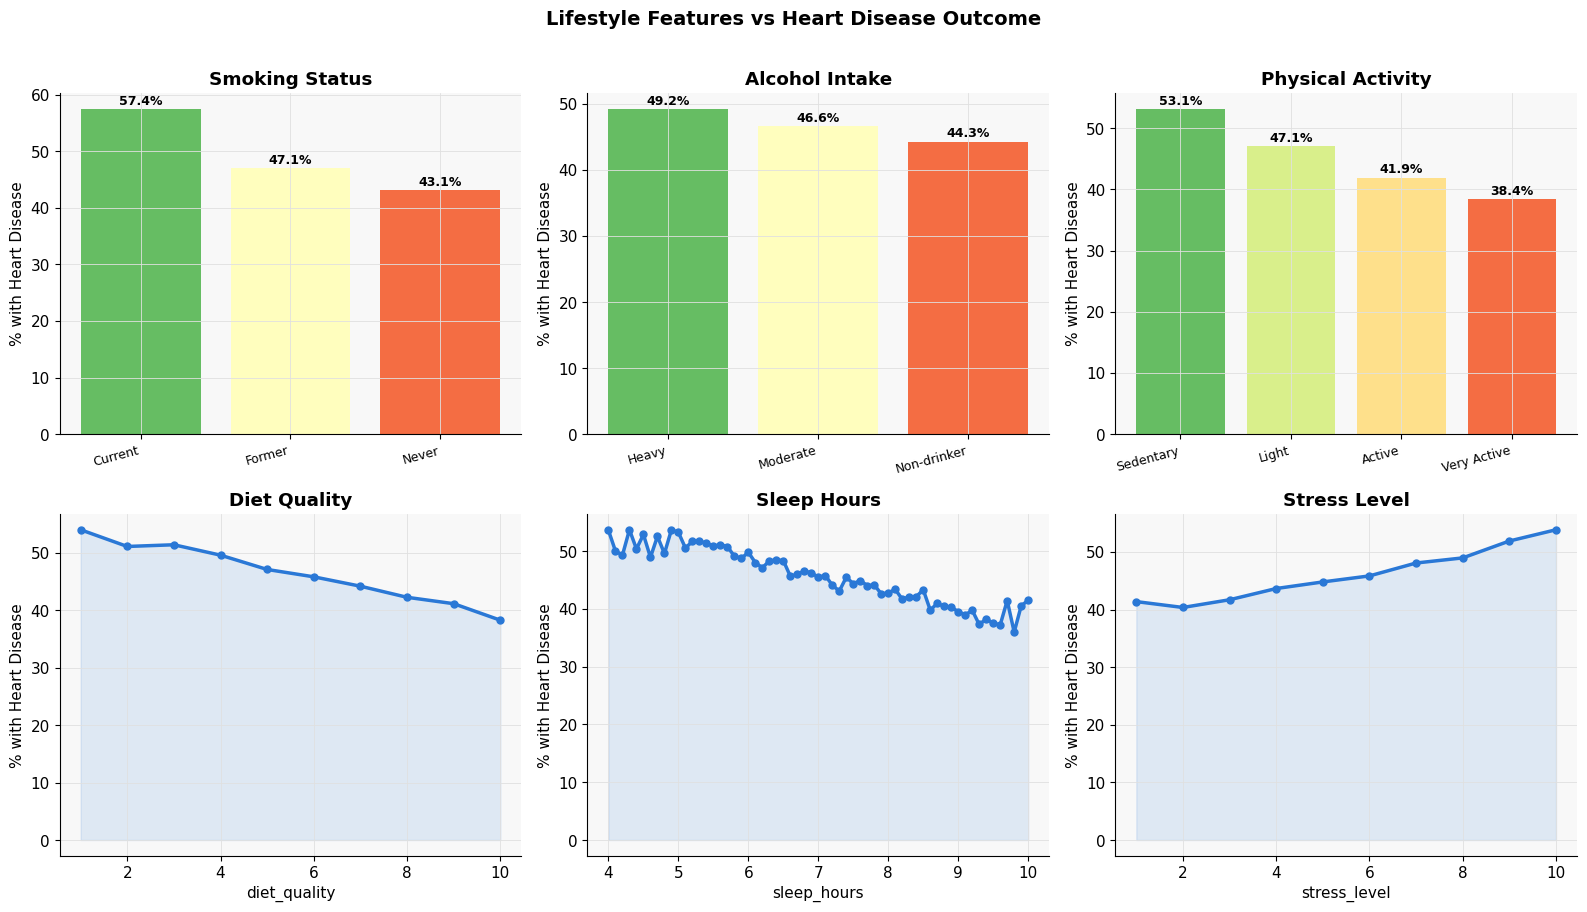

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

lifestyle_cat = ['smoking_status', 'alcohol_intake', 'physical_activity']
lifestyle_num = ['diet_quality', 'sleep_hours', 'stress_level']

for i, col in enumerate(lifestyle_cat):
    hd_rate = df.groupby(col)['heart_disease'].mean().sort_values(ascending=False)
    colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(hd_rate)))
    bars = axes[i].bar(range(len(hd_rate)), hd_rate.values*100,
                       color=colors, edgecolor='none')
    axes[i].set_xticks(range(len(hd_rate)))
    axes[i].set_xticklabels(hd_rate.index, rotation=15, ha='right', fontsize=9)
    axes[i].set_title(col.replace('_',' ').title(), fontweight='bold')
    axes[i].set_ylabel('% with Heart Disease')
    for bar, val in zip(bars, hd_rate.values*100):
        axes[i].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                     f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

for i, col in enumerate(lifestyle_num, start=3):
    hd_rate = df.groupby(col)['heart_disease'].mean()
    axes[i].plot(hd_rate.index, hd_rate.values*100,
                 color=PALETTE[0], linewidth=2.5, marker='o', markersize=5)
    axes[i].fill_between(hd_rate.index, hd_rate.values*100, alpha=0.12, color=PALETTE[0])
    axes[i].set_title(col.replace('_',' ').title(), fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('% with Heart Disease')

plt.suptitle('Lifestyle Features vs Heart Disease Outcome', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 7. Medical History

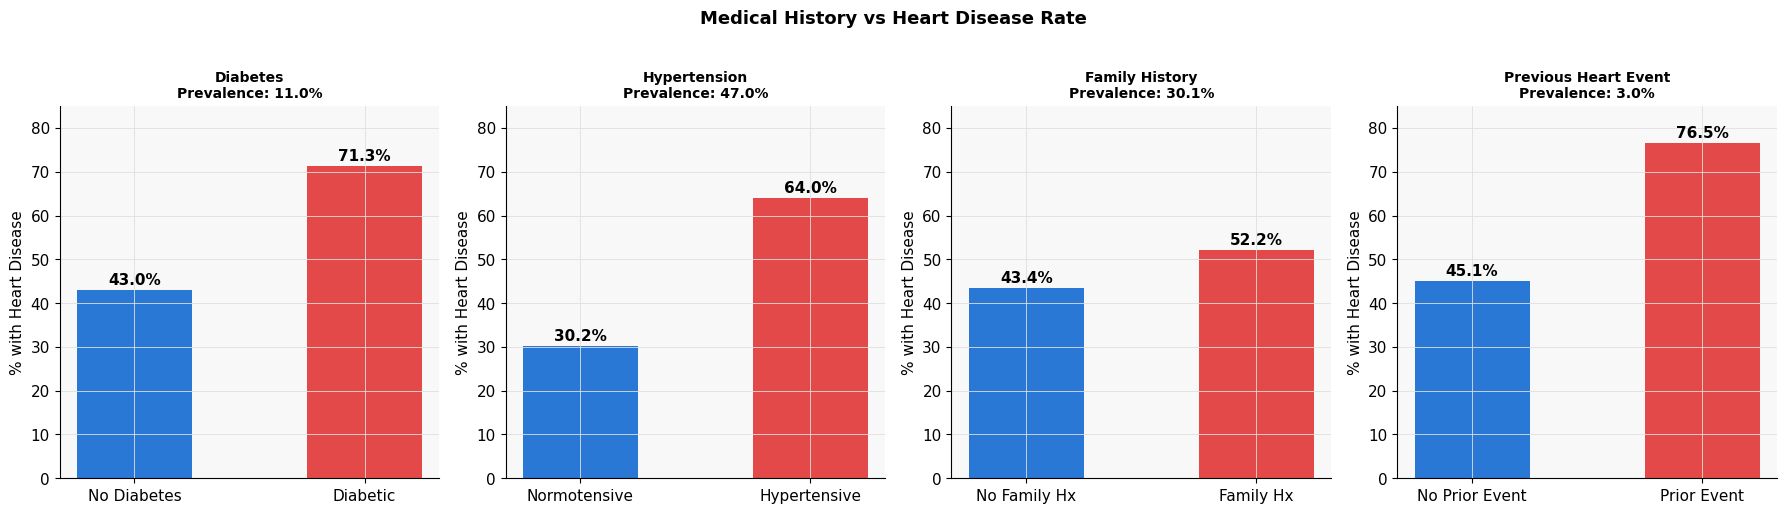

In [ ]:
med_cols = ['diabetes', 'hypertension', 'family_history', 'previous_heart_event']
labels_map = {
    'diabetes': ('No Diabetes', 'Diabetic'),
    'hypertension': ('Normotensive', 'Hypertensive'),
    'family_history': ('No Family Hx', 'Family Hx'),
    'previous_heart_event': ('No Prior Event', 'Prior Event')
}

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, med_cols):
    rates = df.groupby(col)['heart_disease'].mean() * 100
    lb = labels_map[col]
    bars = ax.bar([lb[0], lb[1]], [rates[0], rates[1]],
                  color=[NEG_COLOR, POS_COLOR], width=0.5, edgecolor='none')
    for bar, val in zip(bars, [rates[0], rates[1]]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
    prev = df[col].mean()*100
    ax.set_title(f'{col.replace("_"," ").title()}\nPrevalence: {prev:.1f}%',
                 fontweight='bold', fontsize=10)
    ax.set_ylabel('% with Heart Disease')
    ax.set_ylim(0, 85)

plt.suptitle('Medical History vs Heart Disease Rate', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Wearable Signals

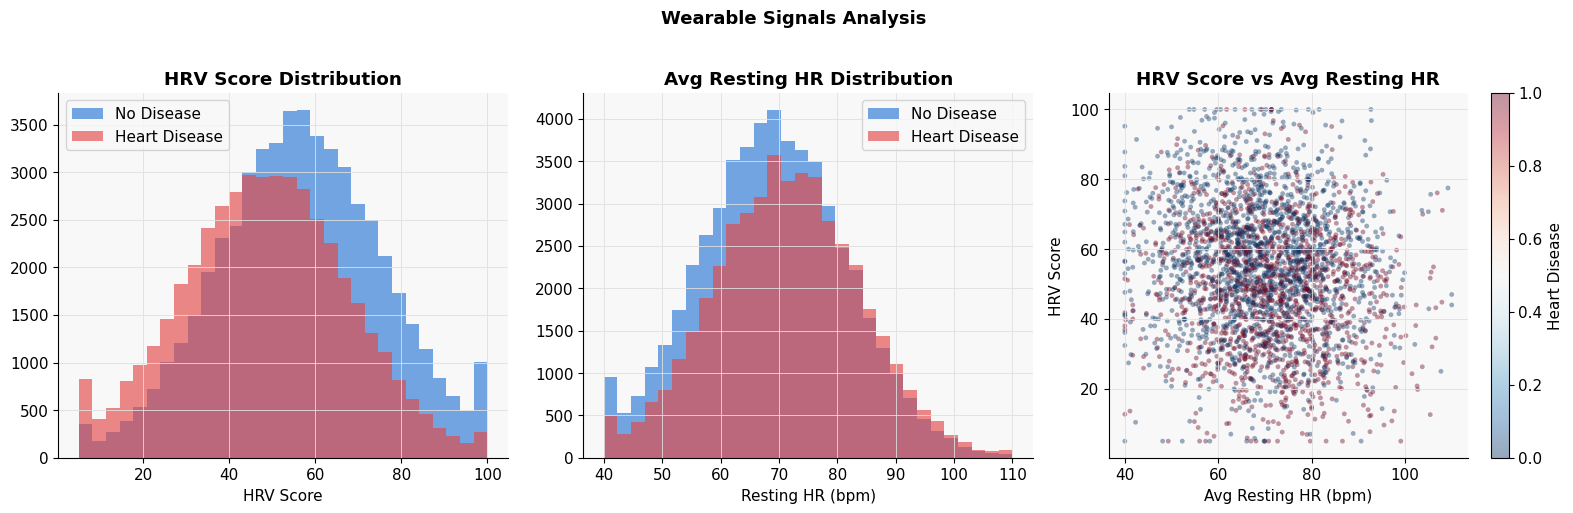

Key wearable insights:
  hrv_score: No HD = 56.5  |  Heart Disease = 48.5
  avg_resting_hr: No HD = 69.0  |  Heart Disease = 71.3


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# HRV distribution
for status, color, label in [(0, NEG_COLOR, 'No Disease'), (1, POS_COLOR, 'Heart Disease')]:
    axes[0].hist(df[df.heart_disease==status]['hrv_score'], bins=30,
                 alpha=0.65, color=color, label=label, edgecolor='none')
axes[0].set_title('HRV Score Distribution', fontweight='bold')
axes[0].set_xlabel('HRV Score')
axes[0].legend()

# Resting HR distribution
for status, color, label in [(0, NEG_COLOR, 'No Disease'), (1, POS_COLOR, 'Heart Disease')]:
    axes[1].hist(df[df.heart_disease==status]['avg_resting_hr'], bins=30,
                 alpha=0.65, color=color, label=label, edgecolor='none')
axes[1].set_title('Avg Resting HR Distribution', fontweight='bold')
axes[1].set_xlabel('Resting HR (bpm)')
axes[1].legend()

# HRV vs resting HR scatter
sample = df.sample(3000, random_state=42)
sc = axes[2].scatter(sample['avg_resting_hr'], sample['hrv_score'],
                     c=sample['heart_disease'], cmap='RdBu_r',
                     alpha=0.4, s=12, edgecolors='none')
plt.colorbar(sc, ax=axes[2], label='Heart Disease')
axes[2].set_title('HRV Score vs Avg Resting HR', fontweight='bold')
axes[2].set_xlabel('Avg Resting HR (bpm)')
axes[2].set_ylabel('HRV Score')

plt.suptitle('Wearable Signals Analysis', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Key wearable insights:")
for col in ['hrv_score', 'avg_resting_hr']:
    no_hd = df[df.heart_disease==0][col].mean()
    yes_hd = df[df.heart_disease==1][col].mean()
    print(f"  {col}: No HD = {no_hd:.1f}  |  Heart Disease = {yes_hd:.1f}")

## 9. Correlation Analysis

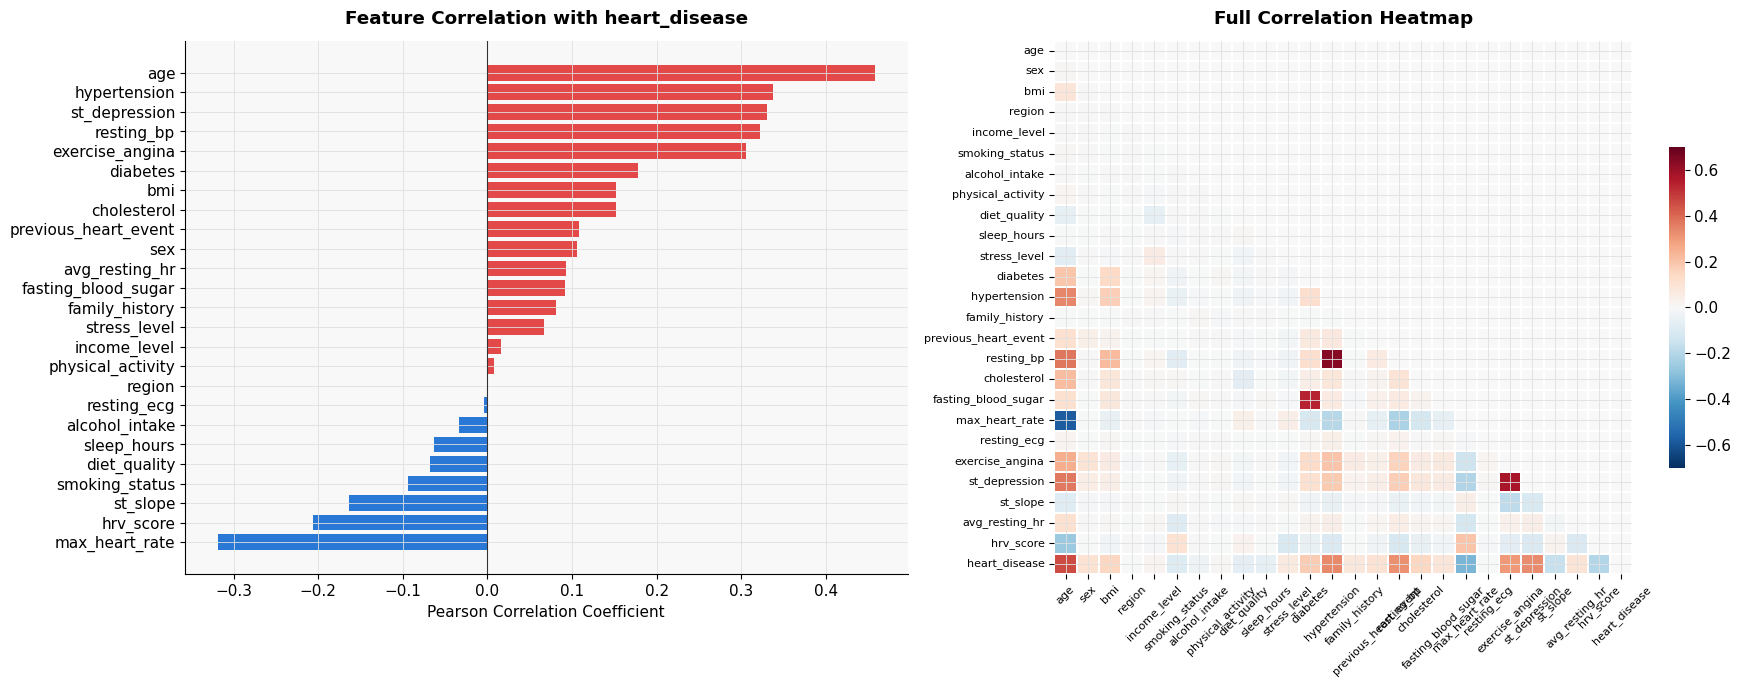

In [ ]:
# Encode categoricals for correlation
df_enc = df.copy()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col])

corr = df_enc.corr()

# Correlation with target
target_corr = corr['heart_disease'].drop('heart_disease').sort_values()
colors = [POS_COLOR if v > 0 else NEG_COLOR for v in target_corr.values]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].barh(target_corr.index, target_corr.values, color=colors, edgecolor='none')
axes[0].axvline(0, color='#333', linewidth=0.8)
axes[0].set_title('Feature Correlation with heart_disease', fontweight='bold', pad=12)
axes[0].set_xlabel('Pearson Correlation Coefficient')

# Full heatmap (numeric only)
num_cols = df_enc.select_dtypes(include=np.number).columns
mask = np.triu(np.ones_like(df_enc[num_cols].corr(), dtype=bool))
sns.heatmap(df_enc[num_cols].corr(), mask=mask, ax=axes[1],
            cmap='RdBu_r', center=0, vmin=-0.7, vmax=0.7,
            linewidths=0.3, linecolor='white',
            cbar_kws={'shrink': 0.6})
axes[1].set_title('Full Correlation Heatmap', fontweight='bold', pad=12)
axes[1].tick_params(axis='x', rotation=45, labelsize=8)
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

## 10. Feature Importance (Random Forest)

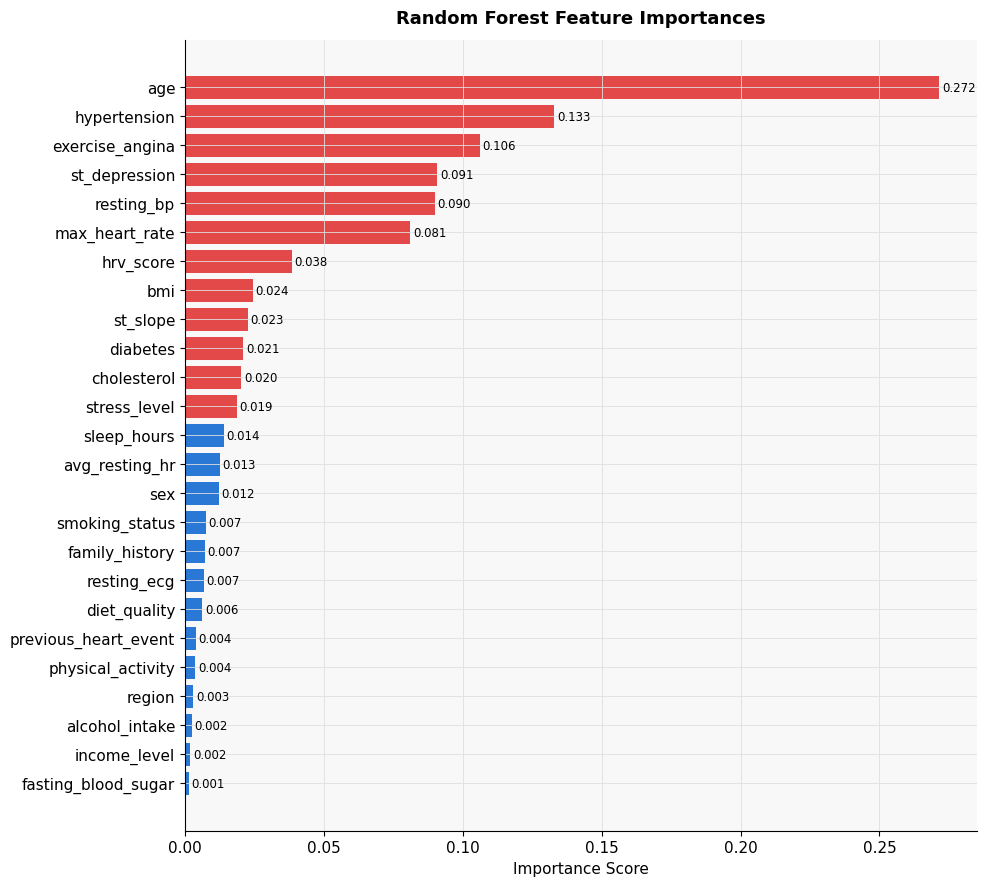

Top 10 features:
age                0.271527
hypertension       0.132946
exercise_angina    0.106181
st_depression      0.090778
resting_bp         0.089953
max_heart_rate     0.081012
hrv_score          0.038353
bmi                0.024345
st_slope           0.022523
diabetes           0.020886


In [ ]:
df_enc = df.copy()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col])

X = df_enc.drop('heart_disease', axis=1)
y = df_enc['heart_disease']

rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X, y)

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
colors = [POS_COLOR if v > importance.median() else PALETTE[0] for v in importance.values]

fig, ax = plt.subplots(figsize=(10, 9))
bars = ax.barh(importance.index, importance.values, color=colors, edgecolor='none')
ax.set_title('Random Forest Feature Importances', fontweight='bold', pad=12, fontsize=13)
ax.set_xlabel('Importance Score')
for bar, val in zip(bars, importance.values):
    ax.text(bar.get_width()+0.001, bar.get_y()+bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=8.5)
plt.tight_layout()
plt.show()

print("Top 10 features:")
print(importance.sort_values(ascending=False).head(10).to_string())

## 11. Baseline Models

We compare two classic approaches: Logistic Regression (interpretable) vs Random Forest (powerful).

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

df_enc = df.copy()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col])

X = df_enc.drop('heart_disease', axis=1)
y = df_enc['heart_disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

# Logistic Regression
lr_pipe = Pipeline([('scaler', StandardScaler()),
                    ('lr', LogisticRegression(max_iter=1000, random_state=42))])
lr_pipe.fit(X_train, y_train)
lr_preds = lr_pipe.predict(X_test)
lr_proba = lr_pipe.predict_proba(X_test)[:,1]
lr_auc   = roc_auc_score(y_test, lr_proba)

# Random Forest
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train)
rf_preds = rf_clf.predict(X_test)
rf_proba = rf_clf.predict_proba(X_test)[:,1]
rf_auc   = roc_auc_score(y_test, rf_proba)

print(f"Logistic Regression  — ROC-AUC: {lr_auc:.4f}")
print(f"Random Forest        — ROC-AUC: {rf_auc:.4f}")
print()
print("=== Logistic Regression Classification Report ===")
print(classification_report(y_test, lr_preds, target_names=['No Disease','Heart Disease']))
print("=== Random Forest Classification Report ===")
print(classification_report(y_test, rf_preds, target_names=['No Disease','Heart Disease']))

Logistic Regression  — ROC-AUC: 0.8505
Random Forest        — ROC-AUC: 0.8416

=== Logistic Regression Classification Report ===
               precision    recall  f1-score   support

   No Disease       0.78      0.80      0.79     10784
Heart Disease       0.76      0.73      0.74      9216

     accuracy                           0.77     20000
    macro avg       0.77      0.77      0.77     20000
 weighted avg       0.77      0.77      0.77     20000

=== Random Forest Classification Report ===
               precision    recall  f1-score   support

   No Disease       0.77      0.80      0.78     10784
Heart Disease       0.76      0.71      0.73      9216

     accuracy                           0.76     20000
    macro avg       0.76      0.76      0.76     20000
 weighted avg       0.76      0.76      0.76     20000



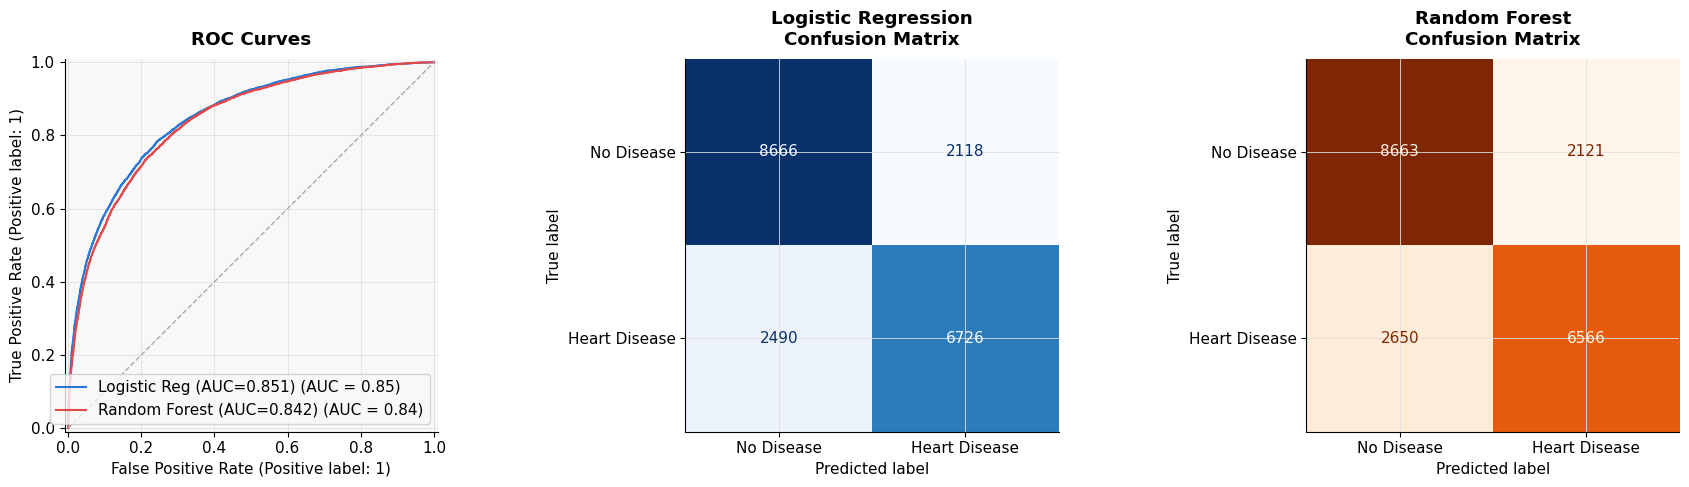

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC curves
RocCurveDisplay.from_predictions(y_test, lr_proba, ax=axes[0],
    name=f'Logistic Reg (AUC={lr_auc:.3f})', color=PALETTE[0])
RocCurveDisplay.from_predictions(y_test, rf_proba, ax=axes[0],
    name=f'Random Forest (AUC={rf_auc:.3f})', color=POS_COLOR)
axes[0].plot([0,1],[0,1],'--',color='#aaa',linewidth=1)
axes[0].set_title('ROC Curves', fontweight='bold', pad=10)

# Confusion matrix — LR
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_preds, ax=axes[1],
    display_labels=['No Disease','Heart Disease'],
    colorbar=False, cmap='Blues')
axes[1].set_title('Logistic Regression\nConfusion Matrix', fontweight='bold', pad=10)

# Confusion matrix — RF
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_preds, ax=axes[2],
    display_labels=['No Disease','Heart Disease'],
    colorbar=False, cmap='Oranges')
axes[2].set_title('Random Forest\nConfusion Matrix', fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

## 12. Key Takeaways

### What this EDA reveals:

| Finding | Detail |
|---|---|
| **Age is the strongest demographic predictor** | Mean age rises ~7 years between no-disease and disease groups |
| **Hypertension doubles risk** | 64.0% HD rate vs 30.2% in normotensive patients |
| **Diabetes raises risk by 66%** | 71.3% HD rate vs 43.0% in non-diabetics |
| **Previous cardiac event is critical** | History of MI/procedure dramatically elevates recurrence probability |
| **HRV is inversely protective** | Heart disease patients show consistently lower HRV scores |
| **Exercise angina is a strong clinical signal** | One of the top 5 features by Random Forest importance |
| **Sleep hours show a U-shape** | Both short (<6h) and long (>9h) sleepers have elevated rates |
| **Income matters** | Low-income patients show higher HD rates, reflecting healthcare access gaps |

### Suggested next steps for competitors:

1. **Feature engineering** - Create interaction terms (age × hypertension, bmi × diabetes)
2. **Hyperparameter tuning** - GridSearchCV or Optuna on XGBoost / LightGBM
3. **Calibration** - Use `CalibratedClassifierCV` for reliable probability outputs
4. **Subgroup fairness** - Check model performance across sex and income groups separately
5. **Ensemble** - Stack LR + RF + XGB for a few more AUC points

---

*Calibrated to CDC, AHA, Framingham, NHANES benchmarks*
